# Numerical Verification — Riski Basrin

## Why am I doing these checks?
I compare the numerical calculation with known answers. These tests use **the same functions as the application**, imported from `simulation.py`. There is no second matrix solver written only for verification.

## 1. Uniform temperature and groundwater flow
Set the entire domain to 100°C. The exact answer is that temperature remains 100°C. I also check intrusion area, inflow/outflow balance, and the absence of water flux through the intrusion.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import json
from pathlib import Path
from checks import basic_checks, sine_test

print(basic_checks())


{'area': 80000.0, 'uniform_error': 1.1368683772161603e-13, 'flow_relative_residual': 1.2250052254028566e-13, 'inflow': 6.521352285082517e-07, 'outflow': 6.521352285082251e-07}


## 2. A case with an analytical solution
For this test, the material is homogeneous and there is no flow. All four boundaries remain at 100°C. The initial temperature is
$$
T(x,z,0)=T_b+100\sin(\pi x/L_x)\sin(\pi z/L_z).
$$
The analytical solution is
$$
T(x,z,t)=T_b+100\sin(\pi x/L_x)\sin(\pi z/L_z)
\exp[-\alpha\pi^2(L_x^{-2}+L_z^{-2})t],
\qquad \alpha=\lambda_h/C_h.
$$
The 100°C amplitude is deliberately chosen for a mathematical test. It is not a field observation or a replacement for the intrusion temperature.

Numerical and analytical parameters, initial conditions, and boundary conditions match. The comparison time is 1,000 years. `sine_test` calls `conduction_operator` and `prepare_conduction` from the application module.


Maximum error: 0.0011663323421942096 °C
RMSE: 0.0005833100851978594 °C


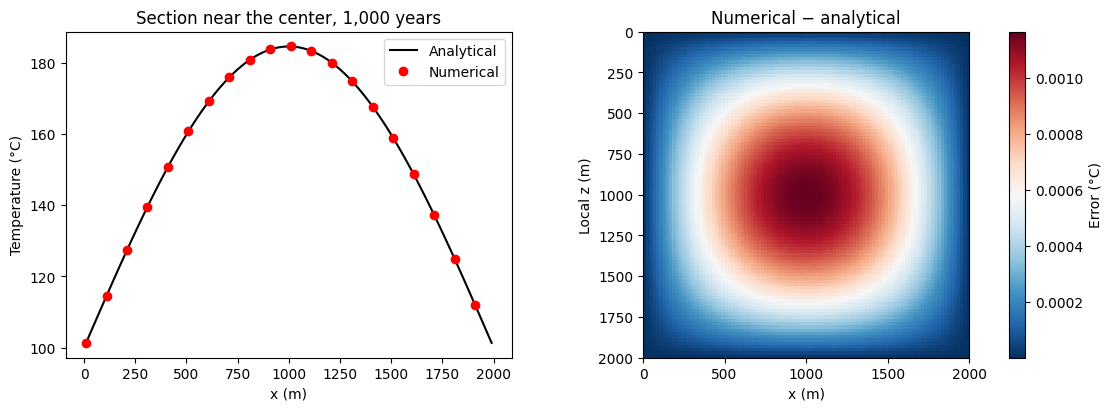

In [2]:
test = sine_test(spacing=20., dt_years=5.)
print("Maximum error:", test["max_error"], "°C")
print("RMSE:", test["rmse"], "°C")

j = len(test["x"]) // 2
fig, axes = plt.subplots(1, 2, figsize=(11, 4), layout="constrained")
axes[0].plot(test["x"], test["exact"][j], "k-", label="Analytical")
axes[0].plot(test["x"][::5], test["numerical"][j, ::5], "ro", label="Numerical")
axes[0].set(xlabel="x (m)", ylabel="Temperature (°C)",
            title="Section near the center, 1,000 years")
axes[0].legend()
im = axes[1].imshow(test["error"], extent=[0, 2000, 2000, 0], cmap="RdBu_r")
axes[1].set(xlabel="x (m)", ylabel="Local z (m)", title="Numerical − analytical")
fig.colorbar(im, ax=axes[1], label="Error (°C)")
plt.show()


## 3. What happens when I refine the grid?
I use dt = 5 years for all three grids. For smooth conduction in homogeneous material, I expect spatial error to decrease by approximately a factor of four when grid spacing is halved.


Grid 40 m | maximum error 0.00466401 °C
Grid 20 m | maximum error 0.00116633 °C
Grid 10 m | maximum error 0.00029102 °C
Ratios: [3.9988699  4.00777353]


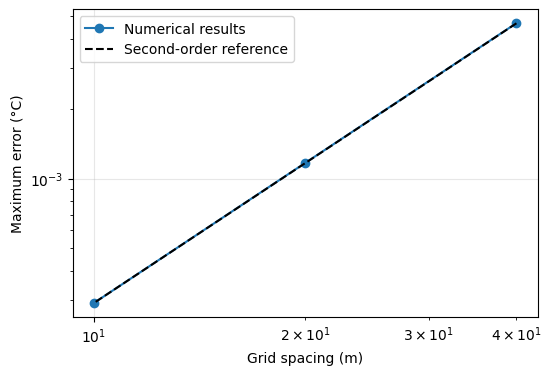

In [3]:
spacings = [40., 20., 10.]
grid_errors = [sine_test(h, 5.)["max_error"] for h in spacings]
for h, error in zip(spacings, grid_errors):
    print(f"Grid {h:.0f} m | maximum error {error:.8f} °C")
print("Ratios:", np.array(grid_errors[:-1]) / grid_errors[1:])
fig, ax = plt.subplots(figsize=(6, 4))
ax.loglog(spacings, grid_errors, "o-", label="Numerical results")
ax.loglog(spacings, grid_errors[-1] * (np.array(spacings) / spacings[-1])**2,
          "k--", label="Second-order reference")
ax.set(xlabel="Grid spacing (m)", ylabel="Maximum error (°C)")
ax.legend(); ax.grid(alpha=.3)
plt.show()


## 4. What happens when I refine the time step?
Spatial error can hide temporal error. I therefore also compare with the exact decay of the **spatially discrete system** on a fixed square grid:
$$
\beta_h=\frac{8\alpha}{\Delta x^2}\sin^2\left(\frac{\pi\Delta x}{2L}\right),
\qquad T_h=T_b+100\sin(\pi x/L)\sin(\pi z/L)e^{-\beta_h t}.
$$
This additional reference isolates time error. The continuous PDE comparison remains above. Large time steps here are used only for the smooth conduction test, not for the intrusion project.


dt 500 years | error against the semidiscrete system 0.00832907 °C
dt 250 years | error against the semidiscrete system 0.00208069 °C
dt 125 years | error against the semidiscrete system 0.00052008 °C
Ratios: [4.00302541 4.00075563]


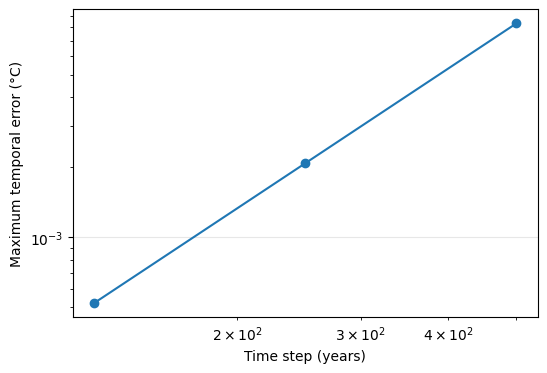

In [4]:
steps = [500., 250., 125.]
time_errors = [sine_test(40., dt)["time_error"] for dt in steps]
for dt, error in zip(steps, time_errors):
    print(f"dt {dt:.0f} years | error against the semidiscrete system {error:.8f} °C")
print("Ratios:", np.array(time_errors[:-1]) / time_errors[1:])
fig, ax = plt.subplots(figsize=(6, 4))
ax.loglog(steps, time_errors, "o-")
ax.set(xlabel="Time step (years)", ylabel="Maximum temporal error (°C)")
ax.grid(alpha=.3)
plt.show()


## 5. Check the actual intrusion model
The following table comes from repeated intrusion runs with the same geometry: a 20 m grid, half the time step on that grid, and a 10 m grid. `build_deliverables.py --recompute` recalculates this table by calling `run_pair` from the application solver.

This checks sensitivity. It does not provide an analytical solution for the intrusion.


In [5]:
summary = json.loads(Path("results/summary.json").read_text())
print("Case | center without flow | center with flow | difference (°C)")
for name, item in summary.items():
    print(name, item["center_no_flow"], item["center_flow"], item["delta"])
delta = summary["grid_20m"]["delta"]
print("Change in the difference from dt/2:",
      abs(summary["grid_20m_dt_half"]["delta"]-delta), "°C")
print("Change in the difference from the 10 m grid:",
      abs(summary["grid_10m"]["delta"]-delta), "°C")


Case | center without flow | center with flow | difference (°C)
grid_20m 140.41635388534624 140.08085959654852 0.3354942887977188
grid_20m_dt_half 140.41635441333068 140.08083131886227 0.3355230944684138
grid_10m 140.41334732151378 140.1311736722427 0.2821736492710727
Change in the difference from dt/2: 2.8805670694964647e-05 °C
Change in the difference from the 10 m grid: 0.05332063952664612 °C


## 6. What can I conclude?
The sinusoidal test checks homogeneous conduction using the same implementation as the application. Error ratios near four support second-order convergence for that smooth test. Uniform temperature and flow balance check basic states, but do not establish full advection accuracy.

Material interfaces, upwind advection, and sequential conduction–advection splitting introduce additional errors. A small difference between cases must be interpreted together with grid sensitivity. Two intrusion resolutions alone do not demonstrate asymptotic convergence or a definitive physical effect.

Heat can leave through the fixed-temperature boundaries, so total heat inside the domain is not expected to remain constant.


## Final results and how I read them

At 5,000 years, the results for an exact 200 × 400 m intrusion are:

| Check | Center without flow (°C) | Center with flow (°C) | Difference (°C) |
|---|---:|---:|---:|
| 20 m grid | 140.416354 | 140.080860 | 0.335494 |
| 20 m grid, dt/2 | 140.416354 | 140.080831 | 0.335523 |
| 10 m grid | 140.413347 | 140.131174 | 0.282174 |

Halving dt on the same grid changes the difference between the cases by 0.000029°C. Refining the grid from 20 m to 10 m changes that difference by 0.053321°C, approximately 15.9% of the 20 m result. On the 10 m grid, dt is also adjusted using the same selection rule.

At both tested resolutions, the center is slightly cooler with flow, and the cooling curves nearly overlap. I do not claim that a particular difference is a converged physical effect. Upwind advection adds numerical diffusion.

The effect in the surrounding rock is different from the center effect. The largest difference between the final maps is approximately 2.838°C on the 20 m grid and 2.830°C on the 10 m grid. This compares the two cases; it is not an error against an exact solution.
